In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os

In [2]:
GAMMA = 'gamma_emp'

## ENCODE QC

In [3]:
rc = pd.read_csv('../../../arkuda_backup/expression/raw/ENCODE/KD/counts.txt',sep='\t',comment='#')

In [4]:
meta = pd.read_csv('../../../arkuda_backup/expression/DE/ENCODE/KD/encode_metadata.tsv',sep='\t')

In [5]:
rc = rc.drop(['Chr','Start','End','Strand','Length'],axis=1).set_index('Geneid')+1
rc.columns = [i[:-4] for i in rc.columns]

In [6]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

sf = get_sf(rc)

''

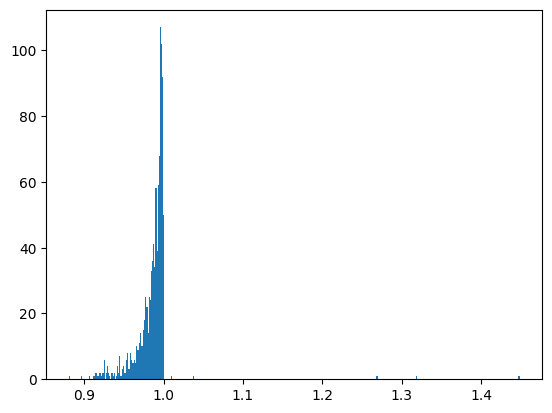

In [7]:
plt.hist(sf,bins=400)
''

In [8]:
expr = rc.div(sf)

In [9]:
genes = (expr>20).mean(axis=1)

(array([43595.,  1416.,   967.,   861.,  1905.,  1610.,   585.,   515.,
          544., 10759.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

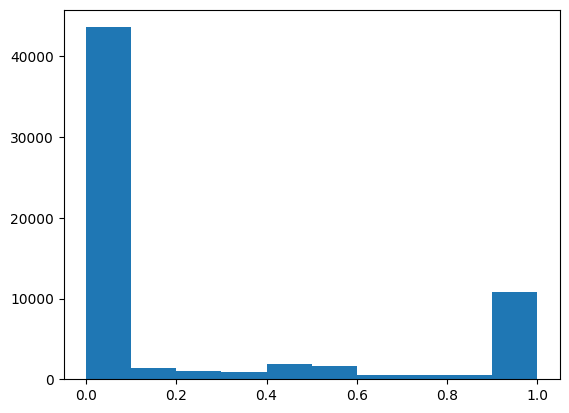

In [10]:
plt.hist(genes)

In [11]:
expr = expr.loc[genes[genes>0.5].index]

In [12]:
%%time
mat = expr.corr()

CPU times: total: 21.9 s
Wall time: 22.3 s


In [13]:
samples = mat.index.to_numpy()
i, j = np.triu_indices(len(samples), k=1)
edges = pd.DataFrame({
    "sample1": samples[i],
    "sample2": samples[j],
    "r": mat.to_numpy()[i, j]
    
})

In [14]:
tmp = meta[['KD_ctrl_id','sample_type','bam_name']]

edges = edges.merge(tmp,left_on="sample1",
                    right_on='bam_name').rename(columns={"sample_type":"sample_type1"}).drop('bam_name',axis=1)
edges = edges.merge(tmp,left_on=["sample2",'KD_ctrl_id'],
                    right_on=['bam_name','KD_ctrl_id']).rename(columns={"sample_type":"sample_type2"}).drop('bam_name', axis=1)

In [15]:
edges['comparison'] = np.where(edges.sample_type1==edges.sample_type2,'same_group','diff_group')

In [16]:
edges = edges.groupby(['KD_ctrl_id','comparison'],as_index=False).r.agg(['min','max','mean']).pivot(index='KD_ctrl_id',
                                                                                                    columns='comparison')

In [17]:
#c1 = (edges[('min','diff_group')]>0.9)
#c2 = (edges[('min','same_group')]>0.99)
#c3 = (edges[('max','diff_group')]<edges[('min','same_group')])

c1 = (edges[('min','diff_group')]>0)
c2 = (edges[('min','same_group')]>0)
c3 = (edges[('max','diff_group')]<edges[('min','same_group')])
(c1&c2&c3).value_counts()

True     382
False     88
Name: count, dtype: int64

In [18]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

# expr: genes x samples dataframe
# meta: dataframe with columns:
#   KD_ctrl_ID, sample_type ('ctrl'/'exp'), bam_name

def experiment_separates(expr_sub, labels, method="average", metric="correlation"):
    """
    Returns True if hierarchical clustering perfectly separates
    ctrl and exp samples into two clusters.
    
    expr_sub: genes x 4 samples dataframe
    labels: list/array of sample labels ('ctrl' or 'exp')
    """
    
    # samples as rows for clustering
    X = expr_sub.T

    # hierarchical clustering
    Z = linkage(pdist(X, metric=metric), method=method)

    # force exactly 2 clusters
    clusters = fcluster(Z, t=2, criterion='maxclust')

    # check if cluster assignment matches labels
    labels = np.array(labels)

    # mapping 1
    ok1 = (
        (clusters[labels == "ctrl"] == clusters[labels == "ctrl"][0]).all()
        and
        (clusters[labels == "exp"] == clusters[labels == "exp"][0]).all()
        and
        (clusters[labels == "ctrl"][0] != clusters[labels == "exp"][0])
    )

    return ok1



In [19]:
selected_experiments = []

for exp_id, submeta in meta.groupby("KD_ctrl_id"):

    # keep only samples present in expr
    samples = [s for s in submeta["bam_name"] if s in expr.columns]

    # require exactly 4 samples (2 ctrl + 2 exp)
    if len(samples) != 4:
        print(exp_id,f"has {len(samples)} samples")
        continue

    labels = (
        submeta.set_index("bam_name")
               .loc[samples, "sample_type"]
               .values
    )

#    # optional: remove low-variance genes
    expr_sub = expr[samples]
#    expr_sub = expr_sub.loc[expr_sub.var(axis=1) > 0]

    # test clustering separation
    if experiment_separates(expr_sub, labels):
        selected_experiments.append(exp_id)

print(f"{len(selected_experiments)} experiments passed clustering criterion")

397 experiments passed clustering criterion


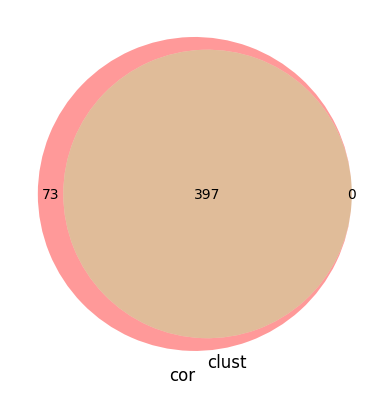

In [20]:
aa = set(edges.loc[c1&c2].index)
bb = set(selected_experiments)
from matplotlib_venn import venn2
venn2([aa,bb],['cor','clust'])

In [21]:
good = edges[c1&c2&c3].index.intersection(selected_experiments)
good = edges[c1&c2].index.intersection(selected_experiments)

In [22]:
len(good),meta.KD_ctrl_id.nunique()

(397, 470)

In [23]:
meta_s = meta[meta.KD_ctrl_id.isin(good)]

In [24]:
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')

In [25]:
expr['geneid'] = expr.index.map(lambda x: x.partition('.')[0])

In [26]:
expr = expr[list(meta_s.bam_name.unique())+['geneid']].groupby('geneid').agg('sum')

In [27]:
expr

,ENCFF036KPI,ENCFF935KUC,ENCFF900FTG,ENCFF458KRT,ENCFF875ZVH,ENCFF413XHF,ENCFF437SBQ,ENCFF511SHN,ENCFF562SON,ENCFF652GQO,...,ENCFF775HZV,ENCFF902YHV,ENCFF634HKB,ENCFF942XPX,ENCFF359FKE,ENCFF303TBG,ENCFF787CCQ,ENCFF279RET,ENCFF279WLO,ENCFF601IUN
geneid,,,,,,,,,,,,,,,,,,,,,
ENSG00000000419,1947.896641,1405.604344,1647.516248,1503.047422,5033.0,1809.781080,1984.628544,1538.132552,1412.670365,1809.373619,...,1735.741555,1977.075828,2532.124890,1706.725878,3183.108635,682.565983,2386.538353,1786.910815,2265.865840,2190.901743
ENSG00000000457,224.718547,181.064446,180.988916,273.556650,552.0,212.320685,400.530483,214.132179,177.622524,318.473869,...,279.925950,121.839474,161.229177,105.091469,367.243279,107.490706,147.838659,248.823067,184.804661,362.480087
ENSG00000000460,376.882226,653.087945,257.521372,536.009524,841.0,125.370309,790.046378,238.259748,383.290709,477.208478,...,908.003530,187.366585,168.463819,76.797612,744.493186,276.251114,298.694434,634.097493,305.329439,948.255919
ENSG00000000971,1.007706,266.886901,1.034222,353.301946,5.0,1.011051,544.721457,1.005315,1.038728,493.282869,...,346.144992,1.023861,1.033520,1.010495,684.453413,350.419702,1.005705,375.241238,1.004373,329.436322
ENSG00000001036,2740.961647,1204.654207,1908.140287,1284.000215,5559.0,3520.479173,2377.148417,2829.962833,1786.612520,1534.099676,...,2013.660868,2210.516164,1772.487423,1300.506930,2180.444425,270.876579,2327.201749,1574.207226,2481.806069,2314.064866
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000291263,18.138717,18.839075,5.171112,61.575482,43.0,21.232069,46.061006,13.069100,13.503467,64.297563,...,70.232317,4.095444,6.201122,16.167918,110.072917,13.973792,16.091283,74.245593,19.083090,90.119359
ENSG00000291272,45.346792,96.288607,38.266228,132.235871,115.0,79.873020,116.153840,101.536855,52.975139,201.934535,...,164.544286,58.360084,41.340815,120.248893,274.181630,27.947584,83.473529,188.623938,69.301748,250.331552
ENSG00000291273,23.177249,32.445074,10.342224,37.349063,98.0,42.464137,7.009283,59.313608,13.503467,49.227822,...,62.205767,15.357917,13.435765,57.598209,72.047728,4.299628,44.251027,59.195810,36.157434,97.128642


In [28]:
d = geneid.set_index('gene_name').gene_id.to_dict()
meta_s['geneid'] = meta_s.target.map(d)

C:\Users\zavil\AppData\Local\Temp\ipykernel_1532\1665814172.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  meta_s['geneid'] = meta_s.target.map(d)


In [29]:
df = expr.loc[expr.index.intersection(meta_s.geneid)].reset_index().melt(id_vars='geneid',var_name='bam_name',value_name='expr')
df = meta_s.merge(df)
df = df.groupby(['KD_ctrl_id','sample_type'],as_index=False).expr.agg('mean').pivot(index='KD_ctrl_id',
                                                                                    columns='sample_type',values='expr')

In [30]:
df['logFC'] = np.log2(df.exp/df.ctrl)

(array([ 1.,  1.,  0.,  1.,  1.,  4.,  7., 13., 18., 25., 31., 50., 53.,
        55., 40., 44., 19., 18.,  4.,  3.]),
 array([-5.24208567, -4.94361253, -4.64513938, -4.34666624, -4.0481931 ,
        -3.74971996, -3.45124682, -3.15277367, -2.85430053, -2.55582739,
        -2.25735425, -1.9588811 , -1.66040796, -1.36193482, -1.06346168,
        -0.76498853, -0.46651539, -0.16804225,  0.13043089,  0.42890403,
         0.72737718]),
 <BarContainer object of 20 artists>)

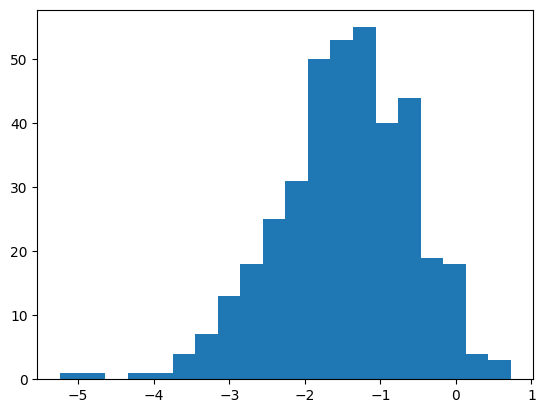

In [31]:
plt.hist(df.logFC,bins=20)

In [32]:
meta[meta.KD_ctrl_id=='ENCSR634KBO_ENCSR572FFX']

,target,cell_line,exper_id,ctrl_id,bam_name,sample_type,replicate,sample_id,KD_ctrl_id
179,HNRNPC,K562,ENCSR634KBO,ENCSR572FFX,ENCFF481NZE,exp,1,477,ENCSR634KBO_ENCSR572FFX
649,HNRNPC,K562,ENCSR634KBO,ENCSR572FFX,ENCFF672FGY,exp,2,669,ENCSR634KBO_ENCSR572FFX
1119,HNRNPC,K562,ENCSR634KBO,ENCSR572FFX,ENCFF568DGW,ctrl,1,555,ENCSR634KBO_ENCSR572FFX
1589,HNRNPC,K562,ENCSR634KBO,ENCSR572FFX,ENCFF691JCT,ctrl,2,685,ENCSR634KBO_ENCSR572FFX


In [33]:
good_exps = df[df.logFC<-1].index

In [34]:
df

sample_type,ctrl,exp,logFC
KD_ctrl_id,,,
ENCSR000KYM_ENCSR913CAE,6548.590551,2255.278687,-1.537879
ENCSR000YYN_ENCSR143COQ,1272.835088,755.642234,-0.752270
ENCSR003LSA_ENCSR104ABF,9579.164723,3884.805522,-1.302057
ENCSR004OSI_ENCSR305XWT,430.434831,123.275902,-1.803904
ENCSR004RGI_ENCSR084SCN,107.298230,95.905760,-0.161937
...,...,...,...
ENCSR995RPB_ENCSR856ZRV,630.792065,381.957743,-0.723751
ENCSR995ZGJ_ENCSR491FOC,676.573519,378.184318,-0.839157
ENCSR997FOT_ENCSR491FOC,4263.497495,706.628828,-2.593013


In [35]:
meta_s = meta[meta.KD_ctrl_id.isin(good_exps)]

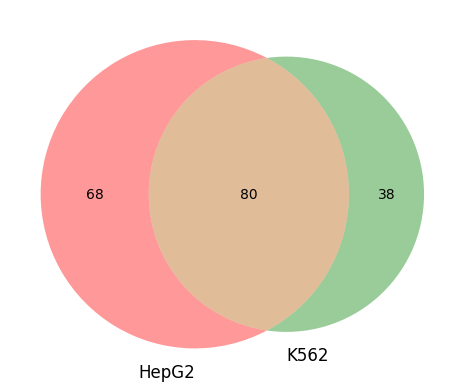

In [36]:
sets = meta_s.groupby('cell_line').target.agg(set)
from matplotlib_venn import venn2
venn2(sets,sets.index)

In [37]:
meta['logFC'] = meta.KD_ctrl_id.map(df.logFC)

## Deseq table

In [38]:
files = list(glob.glob('../../../arkuda_backup/expression/DE/ENCODE/KD/deseq_res_cell_line/*'))

In [39]:
ids = meta[meta.logFC<-3].KD_ctrl_id.tolist()
sfiles = [i for i in files if os.path.basename(i).rpartition('_')[0] in ids]

In [40]:
%%time
de = []
for i in sfiles:
    name = os.path.basename(i).rpartition('_')[0]
    aa = pd.read_csv(i,sep='\t',usecols=['log2FoldChange','padj'])
    aa['gene_id'] = aa.index.map(lambda x: x.split('.')[0])
    aa['KD_ctrl_id'] = name
    de.append(aa)
de = pd.concat(de)

CPU times: total: 531 ms
Wall time: 641 ms


In [41]:
dpsi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/rbpkd_dpsi/ensembl_chess.tsv',sep='\t')

In [42]:
meta['experiment'] = meta.target+'_'+meta.cell_line+'_KD'

In [43]:
mapping = meta[['experiment','KD_ctrl_id']].drop_duplicates()
mapping.nunique()

experiment    470
KD_ctrl_id    470
dtype: int64

In [44]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [45]:
de = de.merge(mapping).drop('KD_ctrl_id',axis=1)

In [46]:
dpsi['dpsi'] = dpsi.exp_psi-dpsi.ctrl_psi

In [106]:
experiment = 'HeLa dKD'
resp = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
resp = resp[resp.experiment==experiment][['src','event_id','experiment','exp_psi','ctrl_psi','prob']]

condition = (resp.exp_psi>0.05)&(resp.prob>0.5)
resp['responder'] = np.where(condition,'R','NR')

gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_gamma_i.tsv',sep='\t')
def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
gamma.experiment = replace(gamma.experiment)
gamma = gamma[['src','event_id','experiment','gamma_i','gamma_emp']]

In [107]:
resp = resp.merge(gamma).drop(['experiment','ctrl_psi','exp_psi'],axis=1)
resp = resp[np.isfinite(resp[GAMMA])].copy()

In [108]:
resp['gamma_bin'] = pd.cut(resp[GAMMA],[0,3,10,30,int(max(resp[GAMMA]))+1])

In [109]:
import gc
gc.collect()

26918

In [110]:
resp = cat.merge(resp)

In [111]:
%%time
m = resp.merge(de).merge(dpsi)

CPU times: total: 734 ms
Wall time: 718 ms


In [112]:
condition = [True]*len(m)
condition = (m.pval<0.05)&(m.padj<1)&(m.dpsi!=0)
tmp = m[condition].copy()

In [113]:
tmp = tmp.sort_values('responder',ascending=False).drop_duplicates(['experiment','gene_id']).iloc[::-1]

In [114]:
tmp

,gene_id,src,event_id,prob,responder,gamma_i,gamma_emp,gamma_bin,log2FoldChange,padj,experiment,exp_psi,ctrl_psi,pval,exp_denom,ctrl_denom,dpsi
0,ENSG00000004534,ensembl,ENSG00000004534_2,3.420434e-15,NR,0.851694,0.646400,"(0, 3]",-0.893143,4.771519e-20,AKAP1_HepG2_KD,0.229193,0.447368,1.489871e-10,195.25,190.00,-0.218175
23800,ENSG00000204628,ensembl,ENSG00000204628_1,9.505085e-01,NR,20.126768,20.447616,"(10, 30]",-0.482632,7.203827e-10,G3BP2_HepG2_KD,0.001909,0.000851,1.037612e-02,6809.50,8816.00,0.001058
7486,ENSG00000113240,ensembl,ENSG00000113240_1,1.631229e-03,NR,1.707182,1.574185,"(0, 3]",0.079788,7.167904e-01,RPS19_K562_KD,0.442623,0.200000,3.868751e-02,15.25,16.25,0.242623
7482,ENSG00000113240,ensembl,ENSG00000113240_0,2.316913e-14,NR,0.483431,0.412085,"(0, 3]",0.884053,1.407693e-08,NAA15_K562_KD,0.025532,0.104265,1.551942e-02,58.75,52.75,-0.078733
7479,ENSG00000113240,ensembl,ENSG00000113240_0,2.316913e-14,NR,0.483431,0.412085,"(0, 3]",0.458384,1.053790e-05,AGGF1_K562_KD,0.031008,0.104265,2.256171e-02,64.50,52.75,-0.073258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20560,ENSG00000173660,ensembl,ENSG00000173660_0,9.645338e-01,R,9.681717,9.663275,"(3, 10]",-0.204595,7.273060e-03,MAGOH_K562_KD,0.078136,0.025518,8.348574e-127,9605.00,10404.50,0.052619
20561,ENSG00000173660,ensembl,ENSG00000173660_0,9.645338e-01,R,9.681717,9.663275,"(3, 10]",-0.222840,1.836830e-01,PABPC1_HepG2_KD,0.158744,0.113823,6.641349e-06,1178.00,1188.25,0.044921
20564,ENSG00000173660,ensembl,ENSG00000173660_0,9.645338e-01,R,9.681717,9.663275,"(3, 10]",0.169596,2.026942e-02,APOBEC3C_K562_KD,0.017570,0.027373,1.136433e-16,13872.75,19736.75,-0.009802
20552,ENSG00000173660,ensembl,ENSG00000173660_0,9.645338e-01,R,9.681717,9.663275,"(3, 10]",-0.568599,1.928082e-09,UBE2L3_HepG2_KD,0.081019,0.060990,3.638099e-04,1512.00,2959.50,0.020028


In [115]:
bins = [-1,-0.2,-0.1,0,0.1,0.2,0.3,1]
#bins = [-1,-0.1,0,0.1,0.2,0.3,1]
tmp['dpsi_bin'] = pd.cut(tmp.dpsi,bins=bins)
aa = tmp['dpsi_bin'].value_counts()
aa.loc[sorted(aa.index)]

dpsi_bin
(-1.0, -0.2]     266
(-0.2, -0.1]     851
(-0.1, 0.0]     2060
(0.0, 0.1]      2975
(0.1, 0.2]      1310
(0.2, 0.3]       444
(0.3, 1.0]       195
Name: count, dtype: int64

In [116]:
import helper_functions as hf
from statsmodels.formula.api import ols
def get_ols_res(formula,df):
    results = ols(formula,df).fit()
    df = pd.DataFrame({
        "coef": results.params,
        "std_err": results.bse,
        "t": results.tvalues,
        "p_value": results.pvalues,
        "ci_lower": results.conf_int()[0],
        "ci_upper": results.conf_int()[1],
    })
    df['adj_R'] = results.rsquared_adj
    df['F_pval'] = results.f_pvalue
    return df

def p2star(p):
    thrs = [0.0001,0.001,0.01,0.05,0.1]
    star = ['****','***','**','*','·']
    for t,s in zip(thrs,star):
        if p<t:
            return s
    return ""


In [122]:
pairs = [((i,'R'),(i,'NR')) for i in tmp.dpsi_bin.unique()]

In [123]:
plt.rcParams.update({'font.size': 14})

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

(-0.1, 0.0]_NR vs. (-0.1, 0.0]_R: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.038e-02 U_stat=4.872e+05
(0.1, 0.2]_NR vs. (0.1, 0.2]_R: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.739e-04 U_stat=2.327e+05
(0.3, 1.0]_NR vs. (0.3, 1.0]_R: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.661e-02 U_stat=5.281e+03
(0.2, 0.3]_NR vs. (0.2, 0.3]_R: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.277e-02 U_stat=2.744e+04


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


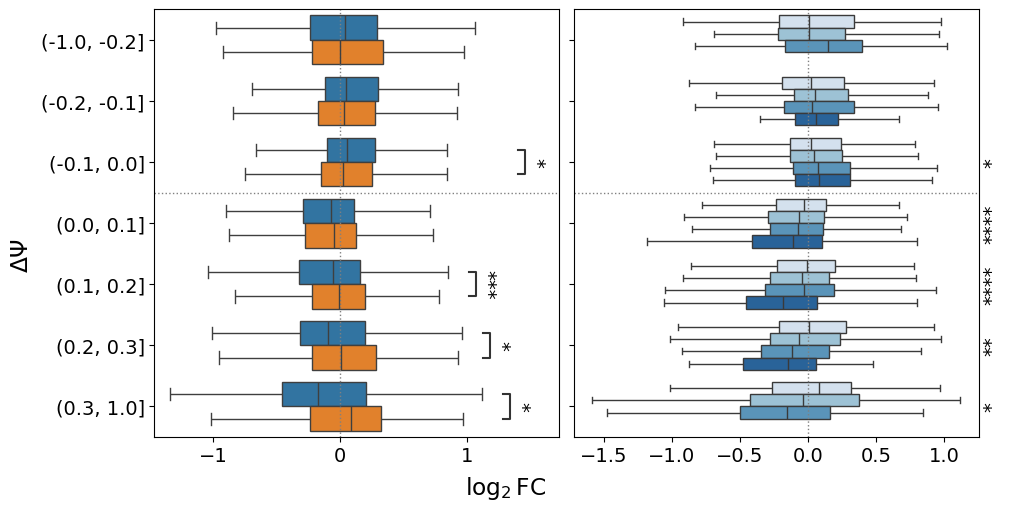

In [124]:
Nmin = 20
f,(ax,ax2) = plt.subplots(1,2,figsize=(10,5),sharey=True,constrained_layout=True)


filt = tmp.groupby(['responder','dpsi_bin'],sort=False,observed=True).size()
filt = filt[filt>Nmin].reset_index().merge(tmp)
filt = filt.sort_values('responder',ascending=True)

sns.boxplot(data=filt,x='log2FoldChange',y='dpsi_bin',hue='responder',hue_order=['R','NR'],showfliers=False,ax=ax,legend=False)
xl = ax.get_xlim()
ax.set_xlim(xl)
ax.axvline(0,lw=1,ls=':',c='grey')
ax.axhline(2.5,lw=1,ls=':',c='grey')

from statannotations.Annotator import Annotator

pairs = [((i,'R'),(i,'NR')) for i in filt.dpsi_bin.unique()]

annotator = Annotator(
    ax,
    pairs,
    data=filt,
    hue="responder",
    x="log2FoldChange",
    y='dpsi_bin',
    orient='h'
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    comparisons_correction="fdr_bh",
    hide_non_significant=True
)

annotator.apply_and_annotate()


tmp[f'{GAMMA}_z'] = np.log10(tmp[GAMMA])
filt = tmp.groupby(['gamma_bin','dpsi_bin'],sort=False,observed=True).size()
filt = filt[filt>Nmin].reset_index().merge(tmp)

sns.boxplot(data=filt,x='log2FoldChange',y='dpsi_bin',hue='gamma_bin',showfliers=False,palette='Blues',ax=ax2)
ax2.axvline(0,lw=1,ls=':',c='grey')
ax2.axhline(2.5,lw=1,ls=':',c='grey')

ps = []


formula = f'log2FoldChange ~ {GAMMA}_z'
for _,aa in filt.groupby('dpsi_bin',observed=True):
    aa[f'{GAMMA}_z'] = (aa[f'{GAMMA}_z']-np.mean(aa[f'{GAMMA}_z']))/np.std(aa[f'{GAMMA}_z'])
    ps.append(hf.get_ols_res(formula,aa).loc[f'{GAMMA}_z','p_value'])
padj = multipletests(ps,method='fdr_bh')[1]

import matplotlib.transforms as transforms

trans = transforms.blended_transform_factory(ax2.transAxes,ax2.transData)
for i,p in enumerate(padj):
    star = hf.p2star(p)
    #ax2.text(1,i,star,ha='right',va='center',transform=trans,rotation=90)
    ax2.text(1.01,i,star,ha='left',va='center',transform=trans,rotation=90)

ax2.legend(title="$\gamma$")

for a in [ax,ax2]:
    a.set_xlabel(None)
    a.set_ylabel(None)

#ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2,title=None)
ax2.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2,title='$\gamma$')
#f.supxlabel('$log_2 FoldChange$')
f.supxlabel(r'$\log_2$FC')
f.supylabel('$\Delta\Psi$')

ax2.get_legend().remove()

In [125]:
f.savefig('./figures/Fig4_ENCODE.pdf',bbox_inches='tight')